In [2]:
import pycsamt
print(pycsamt.__file__)
print(getattr(pycsamt, "__version__", "tidak ada atribut version"))

d:\Maganghub\csamt_v1\lib\site-packages\pycsamt\__init__.py
1.1.2


In [3]:
import os
folder = r"D:\Maganghub\数据XingNing Area\CSAMT数据Xingning\CSAMT数据"   # sesuaikan
for f in os.listdir(folder):
    print(f)

edi_out
K1.AVG
K1.mde
K2.AVG
K2.mde
K3.AVG
K3.mde
K4.AVG
K4.mde
K5.AVG
K5.mde
K6.AVG
K6.mde
K7.AVG
K7.mde
K8.AVG
K8.mde
K9.AVG
K9.mde


In [4]:
mde = r"D:\Maganghub\数据XingNing Area\CSAMT数据Xingning\CSAMT数据\K1.mde"   # sesuaikan nama dan lokasi
with open(mde, "r", errors="ignore") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 20:
            break

$ JOBLINE=LCS01
$ BRGLINE=0
$ BRGBACK=2000
$   UNITS=  m
$ STNLO  =   0
$ STNHI  =   2000
$ STNDELT=   50
$ SurveyType=Scalar
$   TxType=Bipole
$   TxLen= 860
$   TXDIS   =8000M
$   TxBrg= N 54 W
$   TxCX =754693.5
$   TxCY = 2889838
$   Rx2Tx=  North
$   RxLEN=2000
$   RxBrg= N 54 W
$ MODSECT: PlotExport = Surfer
$ MODSECT: LengthUnit = m
$ MODSECT: LNTITLE1 =
$ MODSECT: LNTITLE2 = Line LCS01


In [5]:
import numpy as np

_zeros_like_asli = np.zeros_like
def _zeros_like_aman(a, *args, **kwargs):
    if np.isscalar(a):
        return np.zeros(int(a), *args, **kwargs)
    return _zeros_like_asli(a, *args, **kwargs)
np.zeros_like = _zeros_like_aman

In [6]:
import sys, numpy as np
print(sys.executable)
print(np.__version__)
print(np.__file__)

d:\Maganghub\csamt_v1\Scripts\python.exe
1.23.5
d:\Maganghub\csamt_v1\lib\site-packages\numpy\__init__.py


In [7]:
from pycsamt.ff.core.cs import CSAMT

f = r"D:\Maganghub\数据XingNing Area\CSAMT数据Xingning\CSAMT数据\K1.AVG"
out = r"D:\Maganghub\数据XingNing Area\CSAMT数据Xingning\CSAMT数据\edi_out"

cs = CSAMT(data_fn=f)
cs.avg2edi(data_fn=f, savepath=out)

d:\Maganghub\csamt_v1\lib\site-packages\pycsamt\ff\core\cs.py:989: UserWarning: No station profile file will detected. Be aware sure , we will set location longitude , latitude and elevation to <0.>
  warnings.warn ('No station profile file will detected.'
WEgeophysics-pycsamt[AVG ---> EDI]: 1128B [00:00, 3009.29B/s]                

 completed 
*****************************************************************************
 <47> EDI-outputs saved to 'D:\\Maganghub\\数据XingNing Area\\CSAMT数据Xingning\\CSAMT数据\\edi_out'.
*****************************************************************************


In [8]:
edi_files = [x for x in os.listdir(out) if x.lower().endswith(".edi")]
print(len(edi_files), edi_files[:5])

with open(os.path.join(out, edi_files[0]), errors="ignore") as fh:
    print(fh.read()[:2000])

47 ['S00_emap.2026.edi', 'S01_emap.2026.edi', 'S02_emap.2026.edi', 'S03_emap.2026.edi', 'S04_emap.2026.edi']
>HEAD
  DATAID="S00"
  ACQBY=ZONGE ENGINEERING
  FILEBY=AMTAVG_V.7.76:
  ACQDATE=  99-01-01
  FILEDATE=  11 JUL 17
  PROSPECT=ZONGE
  LOC=K1
  LAT=0:00:00.00
  LONG=0:00:00.00
  ELEV=0.0
  DATUM=WGS84
  UNITS=M
  STDVERS="SEG 1.0"
  COORDSYS=GEOMAGNETIC NORTH
  PROGVERS="pyCSAMT"
  PROGDATE=2026/11/18
  MAXSECT=1000
  EMPTY=1E+32

>INFO
  MAXINFO=999
  PROJECT=CSAMT_SURVEY
  SURVEY=S00
  CREATIONDATE=2026-26-11/18/26 - 02:26:27
  PROCESSEDBY="pyCSAMT"
  PROCESSINGSOFTWARE=AMTAVG_V.7.76:
  PROCESSINGTAG=NONE
  SITENAME=S00
  RUNLIST=NONE
  REMOTEREF=NONE
  REMOTESITE=NONE
  SIGNCONVENTION=EXP(+I \OMEGA T)
  CREATINGSOFTWARE=pyCSAMT

>=DEFINEMEAS
  MAXCHAN=4
  MAXRUN=47
  MAXMEAS=9999
  UNITS=M
  REFTYPE=CARTESIEN
  REFLAT=0:00:00.00
  REFLONG=0:00:00.00
  REFELEV=0.0
>!***CHANNELS USING ORIGINAL SITE LAYOUT. FOR ROTATIONS SEE ZROT***!
>EMEAS  ID=1.001       CHTYPE=        EX  X=-

In [9]:
from pycsamt.ff.processing import Processing
Processing().correct_edi(data_fn=out,
                         number_of_skin_depth=3,
                         dipole_length=50,
                         FILTER='ama')

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
|EDI collected  =  47     |EDI success. read=  47     |Rate     =  100.0  %|
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
** Filter's width              = 268.72 m.


WEgeophysics-pycsamt[---> EDICorrected]: 1128B [00:00, 3038.17B/s]           

 completed
********************************EDI EMAP FILE********************************
** Filter                      = AMA
** Type of correction          = Adaptative moving-average
** Number of skin depth        = 3
** Dipole length               = 50 m.
** Frequency numbers           = 17
** Number of sites processed   = 47
** Save directory              = d:\Maganghub\_coutputEDI_
*****************************************************************************


In [10]:
import pkgutil, pycsamt.modeling as m
for x in pkgutil.walk_packages(m.__path__, prefix="pycsamt.modeling."):
    print(x.name)

pycsamt.modeling.occam2d


In [11]:
import os

base = r"D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert"
crm_files = {
    "mesh_fn": base + r"\Occam.mesh",
    "iter_fn": base + r"\both12.iter",
    "model_fn": base + r"\Occam.model",
    "data_fn": base + r"\Both10km.dat",
}

for key, path in crm_files.items():
  print(f"{key}: {os.path.exists(path)} -> {path}")

mesh_fn: True -> D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert\Occam.mesh
iter_fn: True -> D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert\both12.iter
model_fn: True -> D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert\Occam.model
data_fn: True -> D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert\Both10km.dat


In [12]:
from pycsamt.viewer.plot import Plot2d

print([m for m in dir(Plot2d) if not m.startswith("_")])

['penetration2D', 'plot_Pseudolog', 'plot_Response', 'plot_occam2dModel', 'pseudocrossResPhase']


In [13]:
from pycsamt.viewer.plot import Plot2d
help(Plot2d.plot_occam2dModel)

Help on function plot_occam2dModel in module pycsamt.viewer.plot:

plot_occam2dModel(self, model_fn=None, iter_fn=None, mesh_fn=None, data_fn=None, doi=1000, **kwargs)
    Plotoccam Model  form Occam Model class 
               
    :param model_fn: full path to Occam 2Dmodel file 
    :type model_fn: str  
    
    ==============  =========  =======================================
    Params          Type       Description 
    ==============  =========  =======================================
    iter_fn         str         full path to occam iteration file 
    mesh_fn         str         full path to mesh_fn file 
    data_fn         str         full path to occam_data file 
    doi             str         depth of investigation might 
                                be float or str like "1km" =1000
    depth_scale     str         scale of imaging depth can be 
                                "km" or "m". *Default* is"m"
    ==============  =========  ==============================

In [14]:
import os

base = r"D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert"
src = os.path.join(base, "Occam.model")
dst = os.path.join(base, "Occam_pycsamt.model")

with open(src, "r", encoding="utf8") as f:
    lines = f.readlines()

# buang baris "NUMBER EXCEPTIONS ..." (tanpa titik dua) agar terbaca parser v1
lines = [l for l in lines if "EXCEPTIONS" not in l.upper()]

with open(dst, "w", encoding="utf8") as f:
    f.writelines(lines)

print(len(lines), "baris ditulis ke", dst)

71 baris ditulis ke D:\Maganghub\OCCAM2DMT_V3.0\OCCAM2DMT_V3.0\Binaries\WindowsPC\2Blocks_Invert\Occam_pycsamt.model


In [15]:
import numpy as np
import pycsamt.utils.func_utils as fu

_orig = fu.concat_array_from_list

def _safe(list_of_array, *args, **kwargs):
    if not len(list_of_array):
        return np.array([])
    return _orig(list_of_array, *args, **kwargs)

fu.concat_array_from_list = _safe

----------------------------Occam 2D Mesh params ----------------------------
*** Horizontal nodes read = 134 instead of 135 in mesh files.
*** Vertical nodes read = 51 instead of 52 in mesh files.
---> Horizontal nodes     = 134
---> Vertical nodes       = 51
---Boundaries X (Horizontal nodes)---
** Minimum offset (m)         = -161480.0
** Maximum offset (m)         = 271940.0
----Boundaries Z (Vertical nodes)----
** Minimum depth (m)    = 0.0
** Maximum depth (m)    = 180000.0
---------------------------Occam 2D Models params----------------------------
** Model layer num.            = 31
** Model param count           = 1421.0
** Iteration num.              = 12.0
** Occam Misfit value          = 1.300001
** Occam Misfit reached        = 1.0
** Occam Misfit target         = 1.3
** Occam Roughness params      = 9
-----------------------------Occam 2D Data infos-----------------------------
** Sites num.                  = 11
** Frequencies num.            = 16
** Highest frequency (

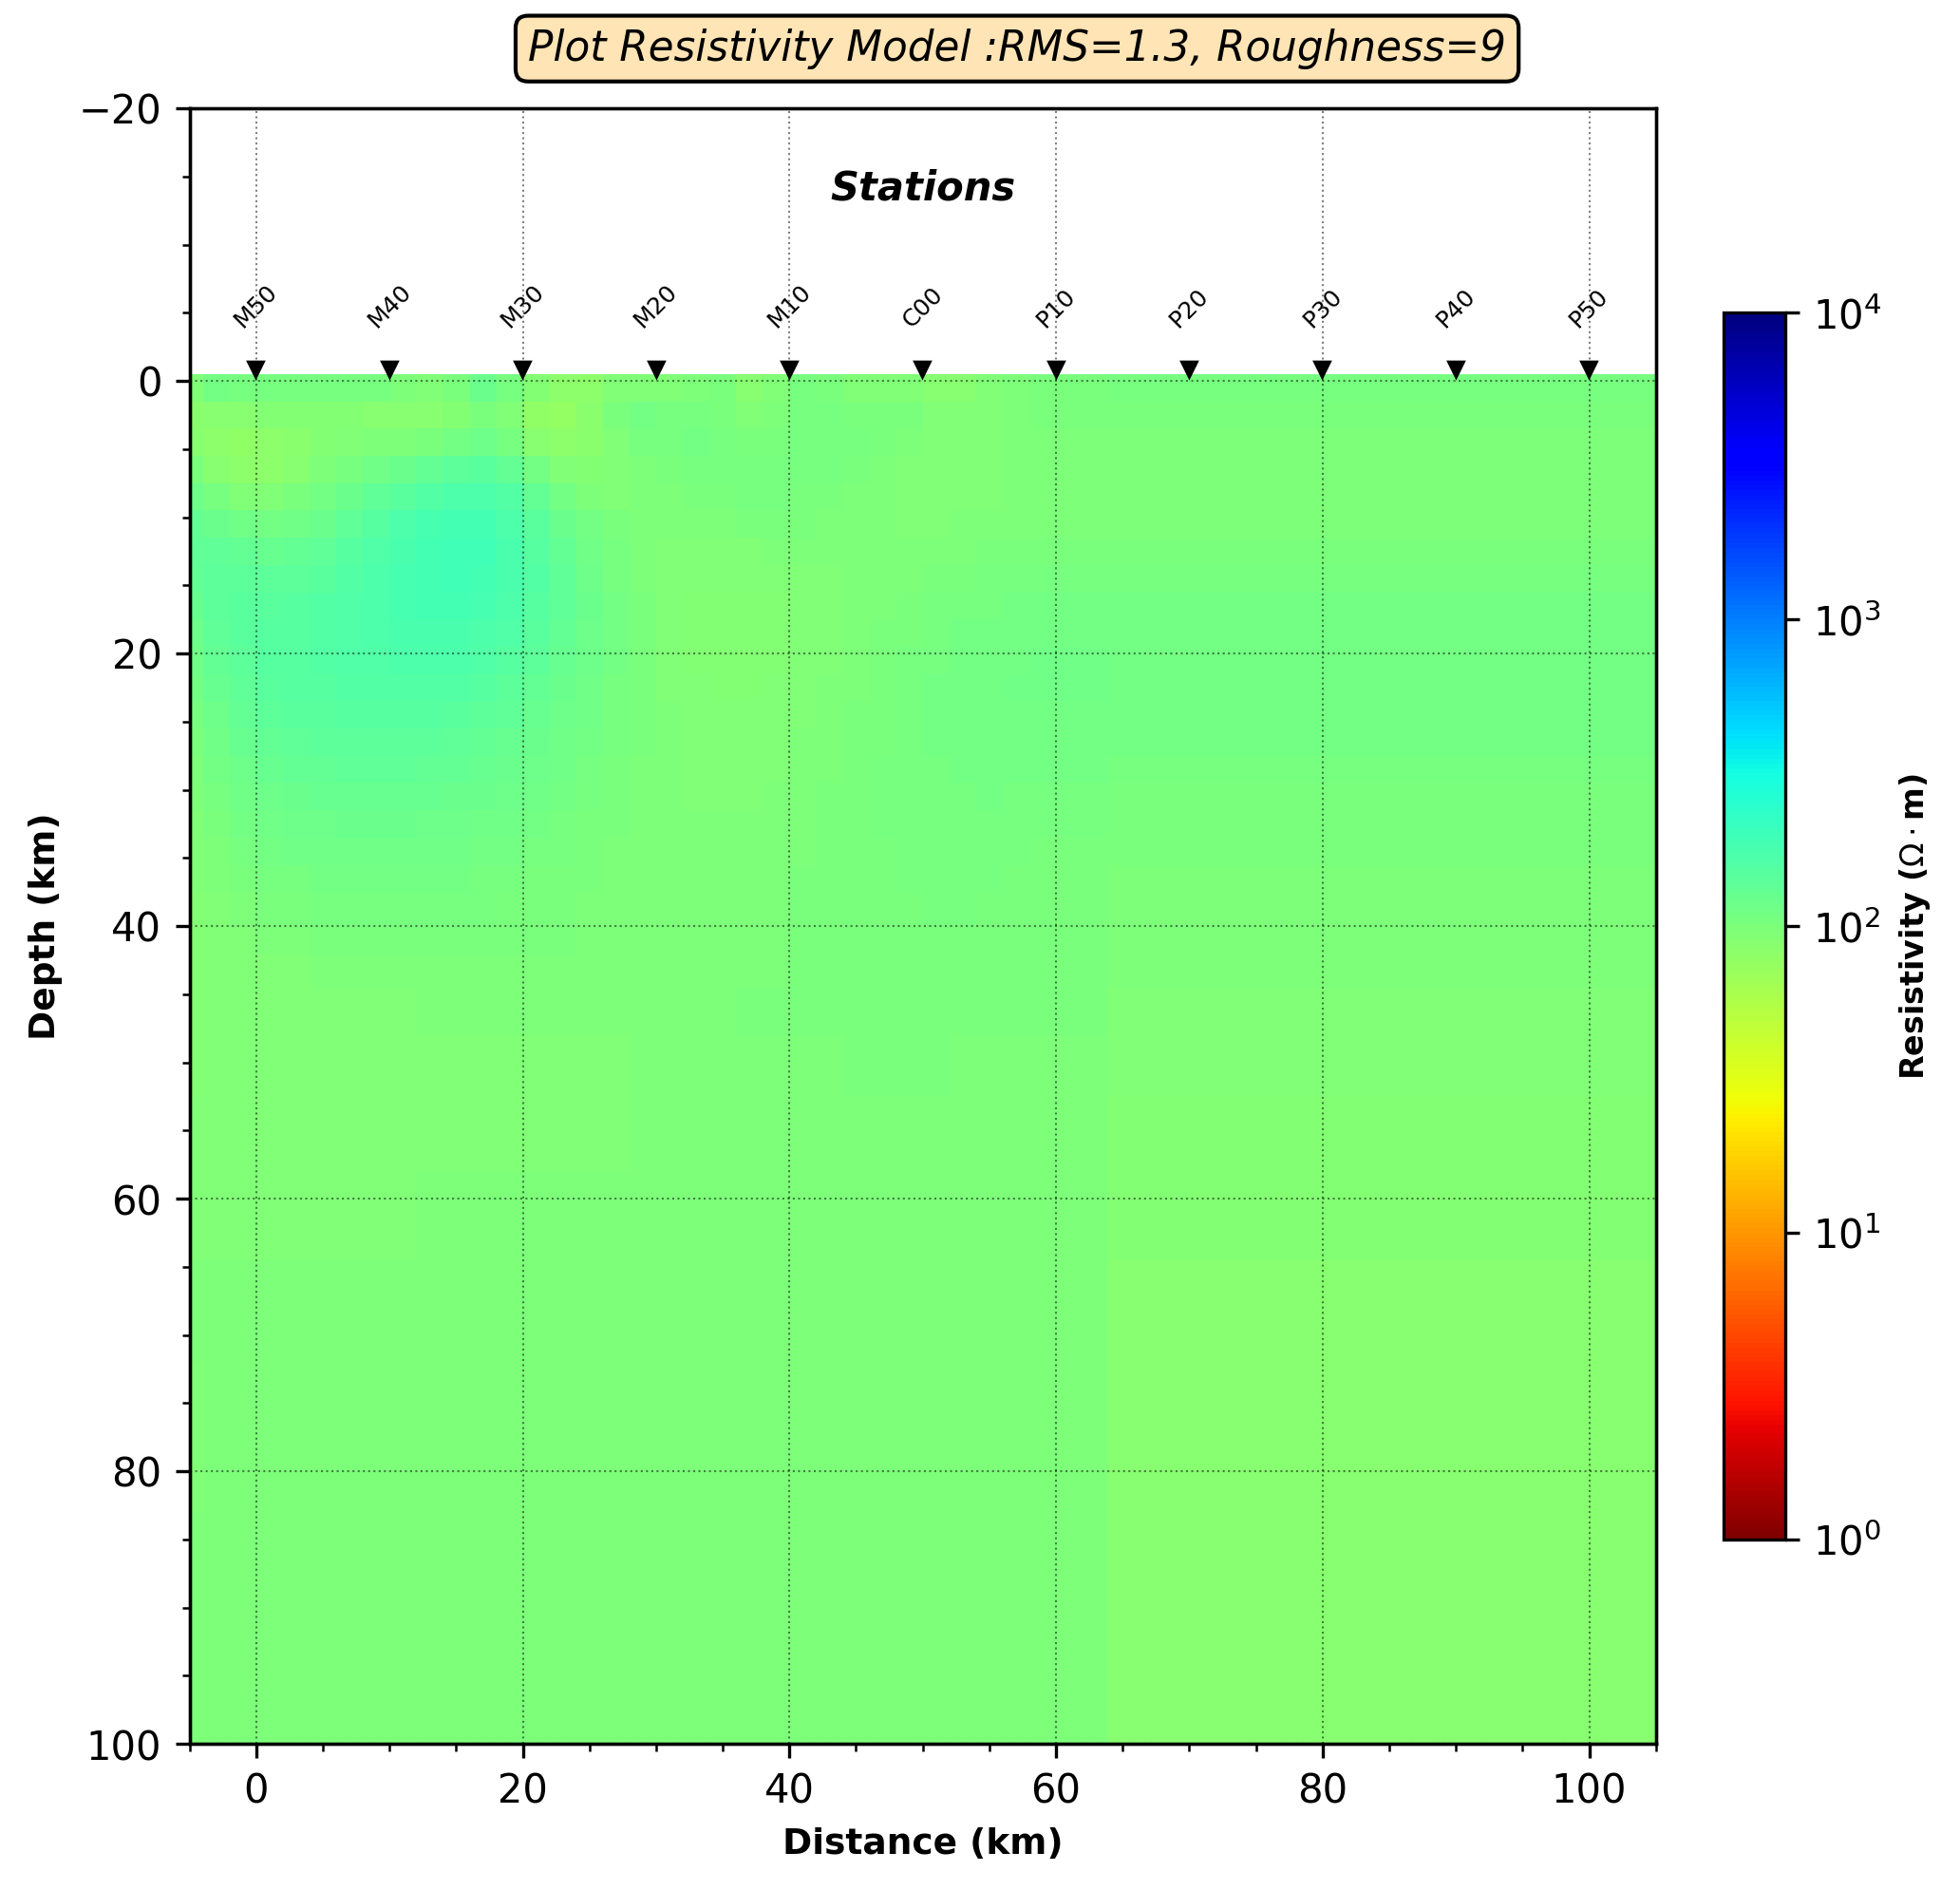

In [ ]:
from pycsamt.viewer.plot import Plot2d

Plot2d().plot_occam2dModel(
    model_fn = os.path.join(base, "Occam_pycsamt.model"),
    iter_fn  = os.path.join(base, "both12.iter"),
    mesh_fn  = os.path.join(base, "Occam.mesh"),
    data_fn  = os.path.join(base, "Both10km.dat"),
    doi      = '50km',
    depth_scale = 'km')